# RetailPulse: Retail Sales & Customer Analytics
**Python · Pandas · NumPy · Matplotlib**

Retrospective portfolio adaptation of a USC MSBA pre-program **team project**.
The course case contains 150 transaction records, 60 registered customers and
53 observed purchasers across 2023. This educational portfolio analysis includes
executed results and charts. The core module also has 12 regression tests on
separately labeled artificial fixtures.

Customer names have been replaced with ID-based labels. The matching customer
source is the course's **Week 5 External** version; the Week 0 file has different
IDs and is not joined. Source fingerprints are recorded in `data/source_manifest.json`.
Team attribution and post-course AI-assisted revisions are documented in
`docs/contributions.md`.

**Questions:** What drives recorded revenue? Where do returns warrant review?
How do customer purchasing patterns differ? What can this sample not establish?

## 1. Setup
Run this notebook from the repository root or its `notebooks/` directory after
installing `requirements.txt`. Put the original `sales_transactions.csv` and
`customers.csv` in `data/`. Personal Google Drive paths are not required.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "retail_analytics.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "retail_analytics.py").exists():
    raise FileNotFoundError("Open this notebook from the repository root or notebooks/ directory.")
sys.path.insert(0, str(ROOT / "src"))
import retail_analytics as ra

DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "outputs"
AS_OF = "2023-12-31"
CARDINAL, GOLD = "#990000", "#FFCC00"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})


## 2. Load and validate
Missing discounts become 0 for the course loading rule and carry a missingness
flag. Discount comparisons keep these records in a separate **Missing discount**
band. Missing ratings stay missing. Invalid dates, duplicate primary keys and
unmatched customers fail explicitly. Formula discrepancies retain source revenue.

In [2]:
tx, customers, audit = ra.load_data(DATA_DIR)
display(pd.Series(audit, name="data_audit").to_frame())
assert audit["join_preserves_transaction_count"]
if audit["revenue_formula_discrepancy_ids"]:
    print("Investigate revenue formula discrepancies before interpreting results.")
if audit["transactions_before_signup"]:
    print("Investigate transactions before signup; signup may mean loyalty enrollment.")
display(tx.head())


,data_audit
transactions,150
customers,60
missing_discounts_filled_with_zero,5
missing_ratings_preserved,8
revenue_formula_discrepancy_ids,"[TXN1008, TXN1073, TXN1074, TXN1120]"
revenue_formula_difference_total,-261.77
transactions_before_signup,9
transaction_date_min,2023-01-01
transaction_date_max,2023-12-29
join_preserves_transaction_count,True


Investigate revenue formula discrepancies before interpreting results.
Investigate transactions before signup; signup may mean loyalty enrollment.


,transaction_id,customer_id,date,region,product,category,quantity,unit_price,discount_pct,revenue,payment_method,returned,customer_rating,discount_was_missing,formula_revenue_with_imputed_discount,revenue_formula_difference,revenue_formula_mismatch
0,TXN1000,C045,2023-03-24,South,Mouse,Accessories,7,28.33,10.0,178.48,Cash,False,NaN,False,178.48,0.0,False
1,TXN1001,C023,2023-10-04,North,Laptop,Computers,4,1069.16,10.0,3848.98,PayPal,False,4.0,False,3848.98,0.0,False
2,TXN1002,C042,2023-09-29,North,Headphones,Audio,8,143.54,0.0,1148.32,PayPal,False,4.0,False,1148.32,0.0,False
3,TXN1003,C053,2023-01-01,South,Monitor,Computers,5,325.93,20.0,1303.72,Debit Card,False,5.0,False,1303.72,-0.0,False
4,TXN1004,C035,2023-11-03,North,Monitor,Computers,7,352.96,0.0,2470.72,Credit Card,False,4.0,False,2470.72,0.0,False


## 3. KPI definitions and overall results
Revenue is the supplied after-discount transaction amount. Refund treatment and
costs are unknown; this is not a profit or verified net-sales measure. Average
transaction value is calculated per unique transaction ID. Rates use transaction
denominators. Ratings use observed responses and show response coverage.

In [3]:
kpis = ra.compute_summary(tx)
tables, payment_diagnostics = ra.build_tables(tx, customers, AS_OF)
display(pd.Series(kpis, name="value").to_frame())
assert tables["customer_summary"]["total_revenue"].sum().round(2) == tx["revenue"].sum().round(2)
for name in ["region_summary", "product_summary", "category_summary"]:
    assert tables[name]["transaction_count"].sum() == len(tx)


,value
transactions,150.000000
purchasing_customers,53.000000
revenue_after_discount,166909.560000
average_transaction_value,1112.730400
return_count,19.000000
return_rate,0.126667
average_observed_rating,3.556338
rating_response_rate,0.946667


## 4. Regions: separate volume, transaction value and returns
Compare total revenue alongside transaction counts and mean transaction values.
A low revenue total alone does not explain regional performance. Return rates
are accompanied by counts because the regional samples are small.

,revenue,transaction_count,average_transaction_value,return_count,return_rate,rated_transactions,average_observed_rating,revenue_share
region,,,,,,,,
South,"$49,033.86",37,"$1,325.24",3,8.1%,35,3.600000,29.4%
East,"$47,602.70",46,"$1,034.84",9,19.6%,45,3.444444,28.5%
North,"$41,642.66",41,"$1,015.67",4,9.8%,37,3.567568,24.9%
West,"$28,630.34",26,"$1,101.17",3,11.5%,25,3.680000,17.2%


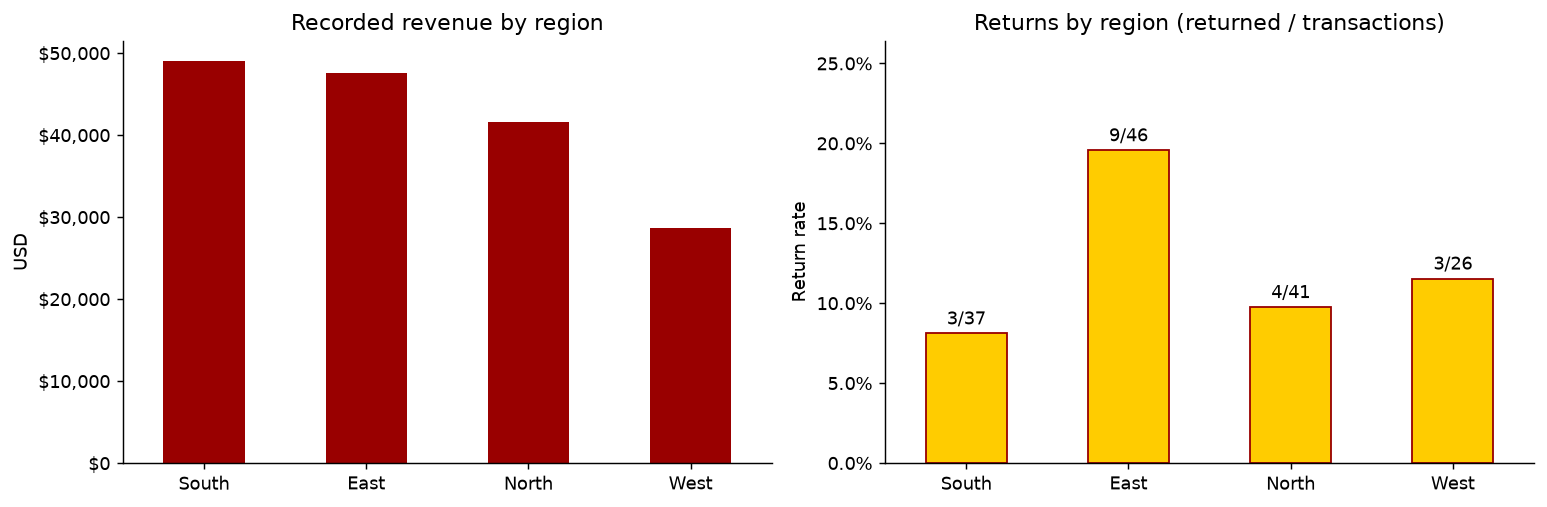

In [4]:
regions = tables["region_summary"].set_index("region")
display(regions.style.format({"revenue": "${:,.2f}", "average_transaction_value": "${:,.2f}", "return_rate": "{:.1%}", "revenue_share": "{:.1%}"}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
regions["revenue"].plot.bar(ax=axes[0], color=CARDINAL, rot=0)
axes[0].set(title="Recorded revenue by region", xlabel="", ylabel="USD")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
regions["return_rate"].plot.bar(ax=axes[1], color=GOLD, edgecolor=CARDINAL, rot=0)
axes[1].set(title="Returns by region (returned / transactions)", xlabel="", ylabel="Return rate")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
for i, (_, row) in enumerate(regions.iterrows()):
    axes[1].annotate(f"{int(row['return_count'])}/{int(row['transaction_count'])}", (i, row["return_rate"]), xytext=(0, 5), textcoords="offset points", ha="center")
axes[1].set_ylim(0, max(0.1, regions["return_rate"].max() * 1.35))
fig.tight_layout()
plt.show()


## 5. Product and category contribution
Revenue share and transaction share answer different questions. A high-price
product can dominate revenue while representing relatively few transactions.
No cost information is available to identify the most profitable product.

,product,revenue,transaction_count,average_transaction_value,return_count,return_rate,rated_transactions,average_observed_rating,revenue_share
0,Laptop,58101.12,12,4841.760000,2,0.166667,12,3.333333,0.348099
1,Monitor,37994.08,19,1999.688421,5,0.263158,19,3.947368,0.227633
2,Tablet,26671.97,13,2051.690000,0,0.000000,12,3.500000,0.159799
3,Headphones,14114.76,17,830.280000,0,0.000000,17,3.882353,0.084565
4,Speaker,8890.85,17,522.991176,2,0.117647,16,3.875000,0.053267
5,Webcam,7187.09,14,513.363571,1,0.071429,13,3.538462,0.043060
6,Keyboard,6639.76,14,474.268571,0,0.000000,13,3.461538,0.039781
7,USB Hub,3024.70,15,201.646667,0,0.000000,15,3.200000,0.018122
8,Mouse,2957.83,20,147.891500,8,0.400000,17,2.823529,0.017721
9,Charger,1327.40,9,147.488889,1,0.111111,8,4.125000,0.007953


region,category,East,North,South,West,Total
0,Accessories,6063.90,6125.51,5022.52,3924.85,21136.78
1,Audio,3985.49,6891.47,6352.49,5776.16,23005.61
2,Computers,37553.31,28625.68,37658.85,18929.33,122767.17
3,Total,47602.70,41642.66,49033.86,28630.34,166909.56


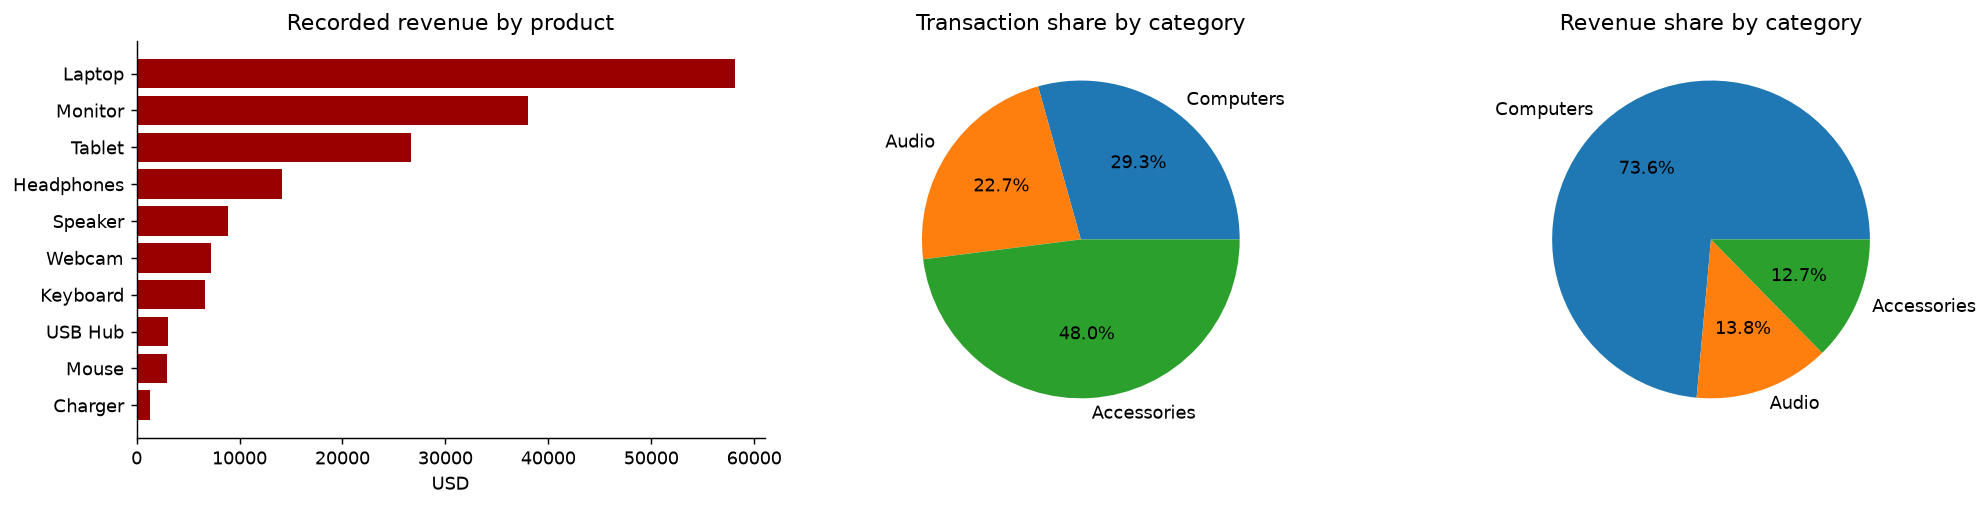

In [5]:
display(tables["product_summary"])
display(tables["category_region_pivot"])
product = tables["product_summary"].sort_values("revenue")
category = tables["category_summary"].set_index("category")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].barh(product["product"], product["revenue"], color=CARDINAL)
axes[0].set(title="Recorded revenue by product", xlabel="USD")
category["transaction_count"].plot.pie(ax=axes[1], autopct="%.1f%%", ylabel="", title="Transaction share by category")
category["revenue"].plot.pie(ax=axes[2], autopct="%.1f%%", ylabel="", title="Revenue share by category")
fig.tight_layout()
plt.show()


## 6. Customer profiles and RFM
All registered customers are retained in summaries. No-purchase customers have
zero observed revenue/counts and undefined return rates. RFM measures recency,
frequency and recorded monetary value at the stated snapshot. It is a heuristic
segmentation, not predicted churn or lifetime value. Equal component values get
equal scores; score bins need not have equal sizes.

Public charts use customer IDs and the included master uses ID-based labels.
Compare the revenue ranking with the RFM ranking: value and recent activity
describe different customer attributes. Signup cohorts summarize the observed
2023 window; these are not retention curves. Nine transactions precede loyalty
signup; this ambiguity is disclosed rather than deleted or silently re-dated.

In [6]:
customer_columns = ["customer_id", "total_revenue", "transaction_count", "average_transaction_value", "return_rate", "rated_transactions", "average_observed_rating", "customer_tier"]
display(tables["top_10_customers"][customer_columns])
display(tables["rfm_scores"].head(10))
display(tables["cohort_summary"])


,customer_id,total_revenue,transaction_count,average_transaction_value,return_rate,rated_transactions,average_observed_rating,customer_tier
18,C019,12680.94,4,3170.235000,0.250000,3,4.000000,Platinum
52,C053,10301.60,4,2575.400000,0.000000,4,3.750000,Platinum
8,C009,9639.87,4,2409.967500,0.000000,3,3.000000,Platinum
32,C033,9465.76,2,4732.880000,0.000000,2,3.000000,Platinum
9,C010,8478.37,3,2826.123333,0.000000,3,4.666667,Platinum
11,C012,8013.98,4,2003.495000,0.000000,3,3.333333,Platinum
15,C016,7084.83,2,3542.415000,0.000000,2,4.500000,Gold
50,C051,6697.51,5,1339.502000,0.400000,5,3.800000,Gold
1,C002,6510.93,3,2170.310000,0.333333,3,3.333333,Gold
24,C025,6341.25,3,2113.750000,0.000000,2,4.000000,Gold


,customer_id,recency_days,transaction_count,total_revenue,purchase_status,R_score,F_score,M_score,RFM_score
50,C051,2.0,5,6697.51,Observed purchaser,5,5,5,15
48,C049,54.0,4,5497.32,Observed purchaser,4,5,5,14
10,C011,8.0,7,5065.53,Observed purchaser,5,5,4,14
52,C053,101.0,4,10301.60,Observed purchaser,3,5,5,13
8,C009,87.0,4,9639.87,Observed purchaser,3,5,5,13
11,C012,100.0,4,8013.98,Observed purchaser,3,5,5,13
53,C054,80.0,4,2416.44,Observed purchaser,4,5,4,13
18,C019,125.0,4,12680.94,Observed purchaser,2,5,5,12
22,C023,27.0,3,4602.19,Observed purchaser,5,3,4,12
36,C037,26.0,3,2172.12,Observed purchaser,5,3,4,12


,signup_cohort,customer_count,average_window_revenue,average_window_transactions
0,2021Q1,4,926.447500,2.000000
1,2021Q2,5,3049.380000,2.400000
2,2021Q3,6,1719.050000,1.333333
3,2021Q4,6,2826.725000,2.833333
4,2022Q1,7,2353.222857,2.571429
5,2022Q2,4,1848.535000,1.750000
6,2022Q3,8,5593.732500,3.250000
7,2022Q4,6,2610.890000,3.000000
8,2023Q1,8,2688.795000,2.500000
9,2023Q2,6,2481.660000,2.666667


## 7. Discounts and customer feedback
Band comparisons are observational; product mix, prices and customer selection
may explain differences. There is no experiment or cost data to establish
incremental discount impact or margin. Five records with unknown discounts are
separated from confirmed 0% transactions. Missing ratings are excluded from rating
denominators and explicitly counted, rather than imputed as customer feedback.

,discount_band,transaction_count,average_transaction_value,average_quantity,return_count,return_rate,average_observed_rating,rated_transactions
0,0%,39,1726.954103,5.974359,5,0.128205,3.459459,37
1,"(0,10]%",52,1071.710000,6.038462,7,0.134615,3.489796,49
2,"(10,20]%",54,775.946111,5.259259,6,0.111111,3.686275,51
3,Missing discount,5,385.668000,8.200000,1,0.200000,3.600000,5


ratings_by_region


,region,transaction_count,rated_transactions,low_rating_count,average_observed_rating,missing_ratings,low_rating_rate_among_rated
0,East,46,45,9,3.444444,1,0.200000
1,North,41,37,7,3.567568,4,0.189189
2,South,37,35,7,3.600000,2,0.200000
3,West,26,25,1,3.680000,1,0.040000


ratings_by_product


,product,transaction_count,rated_transactions,low_rating_count,average_observed_rating,missing_ratings,low_rating_rate_among_rated
0,Charger,9,8,1,4.125000,1,0.125000
1,Headphones,17,17,0,3.882353,0,0.000000
2,Keyboard,14,13,2,3.461538,1,0.153846
3,Laptop,12,12,3,3.333333,0,0.250000
4,Monitor,19,19,1,3.947368,0,0.052632
5,Mouse,20,17,8,2.823529,3,0.470588
6,Speaker,17,16,1,3.875000,1,0.062500
7,Tablet,13,12,2,3.500000,1,0.166667
8,USB Hub,15,15,3,3.200000,0,0.200000
9,Webcam,14,13,3,3.538462,1,0.230769


ratings_by_customer_tier


,customer_tier,transaction_count,rated_transactions,low_rating_count,average_observed_rating,missing_ratings,low_rating_rate_among_rated
0,Bronze,41,39,11,3.358974,2,0.282051
1,Gold,32,31,3,3.709677,1,0.096774
2,Platinum,21,18,2,3.666667,3,0.111111
3,Silver,56,54,8,3.574074,2,0.148148


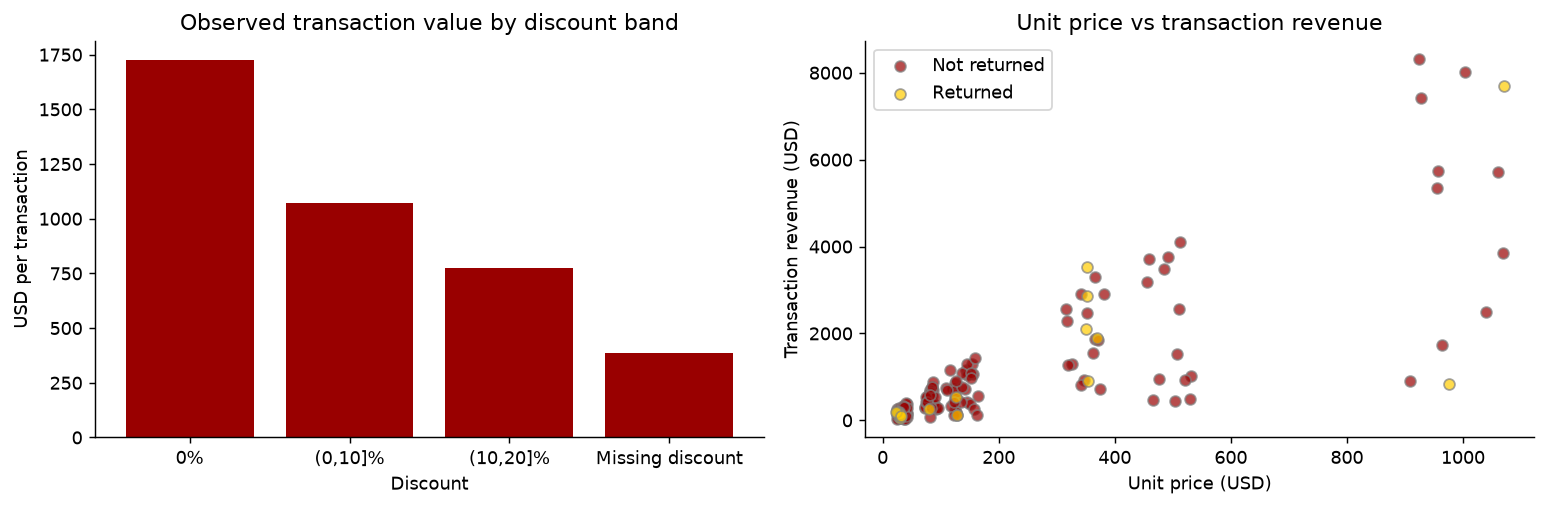

In [7]:
display(tables["discount_summary"])
for name in ["ratings_by_region", "ratings_by_product", "ratings_by_customer_tier"]:
    print(name)
    display(tables[name])
discounts = tables["discount_summary"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(discounts["discount_band"].astype(str), discounts["average_transaction_value"], color=CARDINAL)
axes[0].set(title="Observed transaction value by discount band", xlabel="Discount", ylabel="USD per transaction")
for flag, label, color in [(False, "Not returned", CARDINAL), (True, "Returned", GOLD)]:
    subset = tx.loc[tx["returned"].eq(flag)]
    axes[1].scatter(subset["unit_price"], subset["revenue"], label=label, color=color, edgecolors="gray", alpha=0.7)
axes[1].set(title="Unit price vs transaction revenue", xlabel="Unit price (USD)", ylabel="Transaction revenue (USD)")
axes[1].legend()
fig.tight_layout()
plt.show()


## 8. Monthly activity and descriptive index
Revenue and transaction count are plotted separately. All 12 months and all
category/month combinations are represented. Zero-record months indicate no
activity in the supplied records, not verified business inactivity. One sparse
year does not establish repeating seasonality or justify an inventory forecast.

,month,revenue,transaction_count,average_transaction_value,revenue_change,mom_revenue_change,revenue_index
0,1,16093.23,15,1072.882000,NaN,NaN,1.157026
1,2,18238.81,17,1072.871176,2145.58,0.133322,1.311283
2,3,10011.34,10,1001.134000,-8227.47,-0.451097,0.719768
3,4,11970.58,14,855.041429,1959.24,0.195702,0.860628
4,5,21058.31,13,1619.870000,9087.73,0.759172,1.513992
5,6,4862.25,8,607.781250,-16196.06,-0.769105,0.349573
6,7,7944.75,11,722.250000,3082.50,0.633966,0.571190
7,8,27376.87,14,1955.490714,19432.12,2.445907,1.968266
8,9,20583.46,15,1372.230667,-6793.41,-0.248144,1.479852
9,10,19069.06,17,1121.709412,-1514.40,-0.073574,1.370974


,category,month,revenue,revenue_index
0,Accessories,1,638.75,0.362638
1,Accessories,2,756.30,0.429375
2,Accessories,3,1264.13,0.717685
3,Accessories,4,3534.48,2.006633
4,Accessories,5,1868.73,1.060935
5,Accessories,6,1955.93,1.110442
6,Accessories,7,2679.05,1.520979
7,Accessories,8,1681.82,0.954821
8,Accessories,9,2430.37,1.379796
9,Accessories,10,1910.03,1.084383


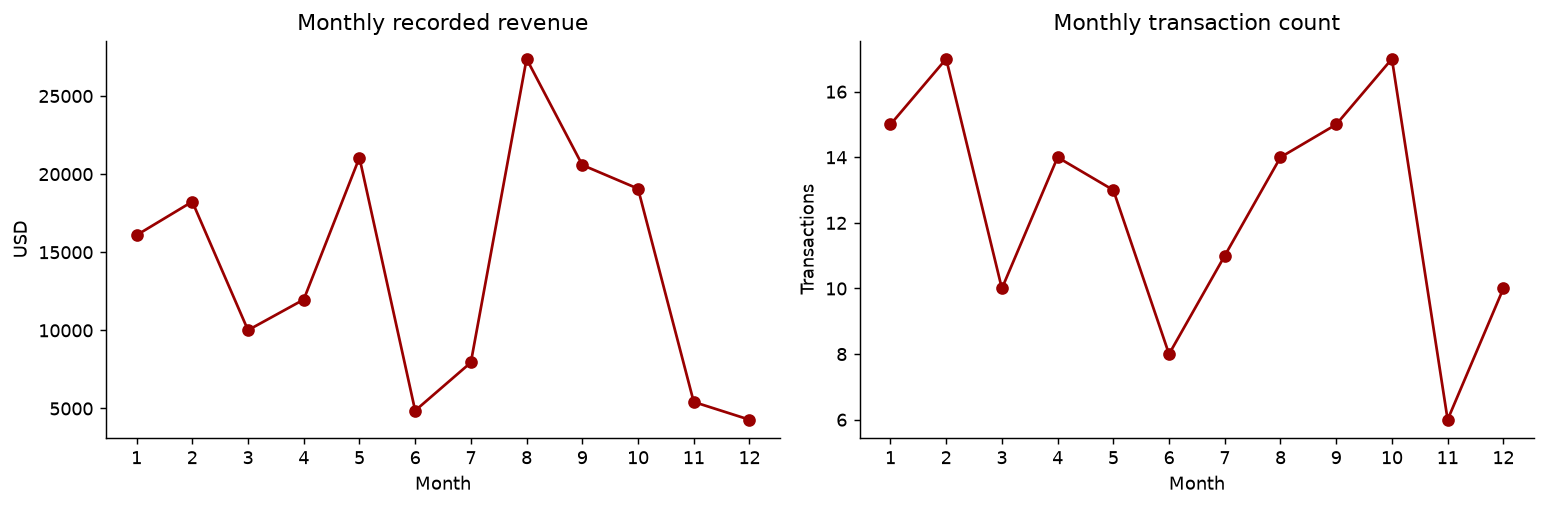

In [8]:
monthly = tables["monthly_summary"]
display(monthly)
display(tables["category_monthly_summary"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(monthly["month"], monthly["revenue"], color=CARDINAL, marker="o")
axes[0].set(title="Monthly recorded revenue", xlabel="Month", ylabel="USD")
axes[1].plot(monthly["month"], monthly["transaction_count"], color=CARDINAL, marker="o")
axes[1].set(title="Monthly transaction count", xlabel="Month", ylabel="Transactions")
for ax in axes:
    ax.set_xticks(range(1, 13))
fig.tight_layout()
plt.show()


## 9. Payment methods and returns: exploratory diagnostics
Read the return numerator and denominator together. The original notebook used
a chi-square p-value as a significance verdict. The revision reports expected
cell-count and repeated-customer diagnostics first. Sparse counts and repeated
customer observations complicate the test assumptions; no standalone significance
or causal claim is made.

In [9]:
display(tables["payment_return_summary"])
display(tables["payment_expected_counts"])
display(pd.Series(payment_diagnostics, name="diagnostic").to_frame())


,payment_method,revenue,transaction_count,average_transaction_value,return_count,return_rate,rated_transactions,average_observed_rating,revenue_share
0,PayPal,51238.85,44,1164.519318,12,0.272727,43,3.488372,0.306986
1,Credit Card,40030.54,34,1177.368824,5,0.147059,32,3.718750,0.239834
2,Cash,38747.73,39,993.531538,1,0.025641,36,3.555556,0.232148
3,Debit Card,36892.44,33,1117.952727,1,0.030303,31,3.483871,0.221033


,payment_method,expected_not_returned,expected_returned
0,Cash,34.060000,4.940000
1,Credit Card,29.693333,4.306667
2,Debit Card,28.820000,4.180000
3,PayPal,38.426667,5.573333


,diagnostic
cells_with_expected_count_below_5,3
total_cells,8
repeated_customers_present,True
interpretation,Descriptive association only; no causal or ind...


## 10. Findings and proposed investigations
**Product concentration:** Laptops generate about 34.8% of recorded revenue on
12 of 150 transactions. Review this high-value product's sales and returns together;
costs would be needed to evaluate profitability.

**West:** It has the lowest recorded revenue and only 26 transactions. Its mean
transaction value is close to the overall average, and its 11.5% return rate is
below the overall 12.7%. Investigate transaction coverage, traffic and conversion
before diagnosing weak pricing or unusually high returns.

**East:** It has 9 returns in 46 transactions (19.6%), versus 10 in the other 104
transactions (9.6%). Review these nine return records and product/payment mix.
This comparison is descriptive and does not identify a cause or measured saving.

**Ratings:** East and South both have 20.0% low ratings among observed responses.
East is not uniquely the highest. Missing ratings are explicitly excluded from
denominators, so these figures differ from the original imputed-rating analysis.

**Data integrity:** Four revenue-formula exceptions all have missing discounts;
source revenue is $261.77 below the formula using a 0% fill. Request the original
discounts and document nine pre-signup transactions before stronger cohort or
discount conclusions. No financial correction is assumed without evidence.

These are retrospective portfolio interpretations. The original personal
reflections and team evaluations are not recreated or represented as coursework.

In [10]:
display(tables["revenue_formula_checks"])
revenue_leader = tables["product_summary"].iloc[0]
east = tables["region_summary"].set_index("region").loc["East"]
print(f"Top product: {revenue_leader['product']} | recorded revenue share {revenue_leader['revenue_share']:.1%}")
print(f"East returns: {int(east['return_count'])}/{int(east['transaction_count'])} ({east['return_rate']:.1%})")
print(f"Formula exceptions: {len(audit['revenue_formula_discrepancy_ids'])}; total difference {audit['revenue_formula_difference_total']:.2f} USD")


,transaction_id,quantity,unit_price,discount_pct,discount_was_missing,revenue,formula_revenue_with_imputed_discount,revenue_formula_difference
8,TXN1008,8,26.66,0.0,True,191.95,213.28,-21.33
73,TXN1073,5,86.19,0.0,True,366.31,430.95,-64.64
74,TXN1074,8,124.66,0.0,True,847.69,997.28,-149.59
120,TXN1120,10,26.21,0.0,True,235.89,262.10,-26.21


Top product: Laptop | recorded revenue share 34.8%
East returns: 9/46 (19.6%)
Formula exceptions: 4; total difference -261.77 USD


## 11. Export case results
Export the validated case tables. Formula exceptions retain source values and
are disclosed separately. The included public inputs use ID-based customer labels.

In [11]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, table in tables.items():
    table.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
print(f"Exported {len(tables)} tables to outputs/")


Exported 17 tables to outputs/
